In [1]:
import tensorflow as tf
print(tf.__version__)
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import sys
import sklearn
from sklearn import metrics
import os
import pandas as pd
import time
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import logging
logging.disable(30)
from collections import  Counter
import math
import random
from fitter import Fitter
random_seed =3407
tf.random.set_seed(random_seed )
os.environ['TF_DETERMINISTIC_OPS'] = '1'
print('ala')

2.9.0


D:\Anaconda3\lib\site-packages\sklearn\linear_model\least_angle.py:30: DeprecationWarning: `np.float` is a deprecated alias for the builtin `float`. To silence this warning, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  method='lar', copy_X=True, eps=np.finfo(np.float).eps,
D:\Anaconda3\lib\site-packages\sklearn\linear_model\least_angle.py:167: DeprecationWarning: `np.float` is a deprecated alias for the builtin `float`. To silence this warning, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  method='lar', copy_X=True, eps=np.finfo(np.float).

ala


In [2]:

source_data=np.load(r"48kcwru_data.npy")
source_label=np.load(r"48kcwru_label.npy")

target_data=np.load(r"seu2_data.npy")
target_label=np.load(r"seu2_label.npy")

source_data.shape,source_label.shape,target_data.shape,target_label.shape


((4000, 3072), (4000, 4), (4000, 3072), (4000, 4))

In [3]:
import scipy.io as scio
import numpy as np
from tensorflow.keras.optimizers import Adam
from sklearn.manifold import TSNE
from tensorflow import keras
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from keras.utils.np_utils import to_categorical

# 0hp-data
normal = scio.loadmat('D-N.mat')['X097_DE_time']

B007 = scio.loadmat('Db7.mat')['X118_DE_time']
B014 = scio.loadmat('Db14.mat')['X185_DE_time']
B021 = scio.loadmat('Db21.mat')['X222_DE_time']

IR007 = scio.loadmat('Di7.mat')['X105_DE_time']
IR014 = scio.loadmat('Di14.mat')['X169_DE_time']
IR021 = scio.loadmat('Di21.mat')['X209_DE_time']

OR007 = scio.loadmat('Do7.mat')['X130_DE_time']
OR014 = scio.loadmat('Do14.mat')['X197_DE_time']
OR021 = scio.loadmat('Do21.mat')['X234_DE_time']

# 用滑窗截取，形成训练样本集
win_len = 3072  # 每个样本的大小（指含有的振动点数）
step = 200  # 滑窗截取时的步长

# 定义 data_sample 制作样本集的函数
def data_sample(data, win_len, step):
    i = 0
    data_sample = []  # 建立一个名字为 data_sample 的空白矩阵
    # 用滑窗截取
    while i < len(data) - win_len:
        data_sample.append(data[i:i + win_len])
        i = i + step
    return data_sample

# 应用制作数据样本的自定义函数 data_sample 生成数据样本
normal_sample = np.array(data_sample(normal, win_len, step))
normal_sample = normal_sample[:600, :, :]

IR007_sample = np.array(data_sample(IR007, win_len, step))
IR007_sample = IR007_sample[:600, :, :]

B007_sample = np.array(data_sample(B007, win_len, step))
B007_sample = B007_sample[:600, :, :]

OR007_sample = np.array(data_sample(OR007, win_len, step))
OR007_sample = OR007_sample[:600, :, :]

IR014_sample = np.array(data_sample(IR014, win_len, step))
IR014_sample = IR014_sample[:600, :, :]

B014_sample = np.array(data_sample(B014, win_len, step))
B014_sample = B014_sample[:600, :, :]

OR014_sample = np.array(data_sample(OR014, win_len, step))
OR014_sample = OR014_sample[:600, :, :]

IR021_sample = np.array(data_sample(IR021, win_len, step))
IR021_sample = IR021_sample[:600, :, :]

B021_sample = np.array(data_sample(B021, win_len, step))
B021_sample = B021_sample[:600, :, :]

OR021_sample = np.array(data_sample(OR021, win_len, step))
OR021_sample = OR021_sample[:600, :, :]

# 输出各故障类别的样本集大小
print('正常数据规模：', normal_sample.shape)
print('0.007英寸内圈故障的数据规模：', IR007_sample.shape)
print('0.021英寸内圈故障的数据规模：', IR021_sample.shape)
print('0.014英寸内圈故障的数据规模：', IR014_sample.shape)
print('0.07英寸外圈故障的数据规模：', OR007_sample.shape)
print('0.021英寸外圈故障的数据规模：', OR021_sample.shape)
print('0.014英寸外圈故障的数据规模：', OR014_sample.shape)
print('0.07英寸滚珠故障的数据规模：', B007_sample.shape)
print('0.021英寸滚珠故障的数据规模：', B021_sample.shape)
print('0.014英寸滚珠故障的数据规模：', B014_sample.shape)

# 制作分类标签
normal_label = [0 for i in range(normal_sample.shape[0])]  # 正常数据的 label 为 0
IR007_label = [1 for i in range(IR007_sample.shape[0])]  # 内圈 0.007，故障数据的 label 为 1
B007_label = [2 for i in range(B007_sample.shape[0])]
OR007_label = [3 for i in range(OR007_sample.shape[0])]
IR014_label = [4 for i in range(IR014_sample.shape[0])]  # 内圈 0.014，故障数据的 label 为 4
B014_label = [5 for i in range(B014_sample.shape[0])]
OR014_label = [6 for i in range(OR014_sample.shape[0])]
IR021_label = [7 for i in range(IR021_sample.shape[0])]  # 内圈 0.021，故障数据的 label 为 7
B021_label = [8 for i in range(B021_sample.shape[0])]
OR021_label = [9 for i in range(OR021_sample.shape[0])]

# 对应制作训练数据和标签数据
x_data = np.vstack((normal_sample, IR007_sample, B007_sample, OR007_sample, IR014_sample, B014_sample, OR014_sample, IR021_sample, B021_sample, OR021_sample))  # 按垂直方向（行顺序）堆叠数组构成一个新的数组
y_data = normal_label + IR007_label + B007_label + OR007_label + IR014_label + B014_label + OR014_label + IR021_label + B021_label + OR021_label
print(x_data.shape, 'x')

# 将标签 one-hot
y_data = to_categorical(y_data, num_classes=10)  # 将 label 转换为 one-hot

# Reshape x_data to remove the extra dimension and get the desired shape (samples, features)
x_data = x_data.reshape(x_data.shape[0], -1)  # Flatten the 3rd dimension

# Train-test split
AX_train, AX_test, Ay_train, Ay_test = train_test_split(x_data, y_data, test_size=0.2)

print('AX_train：', AX_train.shape)
print('AX_test：', AX_test.shape)
print('Ay_train：', Ay_train.shape)
print('Ay_test：', Ay_test.shape)


正常数据规模： (600, 3072, 1)
0.007英寸内圈故障的数据规模： (591, 3072, 1)
0.021英寸内圈故障的数据规模： (596, 3072, 1)
0.014英寸内圈故障的数据规模： (594, 3072, 1)
0.07英寸外圈故障的数据规模： (595, 3072, 1)
0.021英寸外圈故障的数据规模： (597, 3072, 1)
0.014英寸外圈故障的数据规模： (594, 3072, 1)
0.07英寸滚珠故障的数据规模： (598, 3072, 1)
0.021英寸滚珠故障的数据规模： (595, 3072, 1)
0.014英寸滚珠故障的数据规模： (594, 3072, 1)
(5954, 3072, 1) x
AX_train： (4763, 3072)
AX_test： (1191, 3072)
Ay_train： (4763, 10)
Ay_test： (1191, 10)


In [4]:
import scipy.io as scio 
import numpy as np
from tensorflow.keras.optimizers import Adam
from sklearn.manifold import TSNE
from tensorflow import keras
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from keras.utils.np_utils import to_categorical

# -----------------------------
# Helper: Add AWGN at target SNR
# SNR_dB = 10*log10(P_signal / P_noise)
# This function computes signal power per sample window and injects noise
# with variance set to match the requested SNR (in dB).
# -----------------------------
def add_awgn_to_samples(samples, snr_db=3.0, eps=1e-12, seed=None):
    """
    samples: np.ndarray of shape (num_samples, win_len, channels)
    snr_db : target SNR in dB (scalar)
    eps    : small value to avoid division-by-zero
    seed   : optional int for reproducibility
    return : noisy samples with the same shape as input
    """
    if seed is not None:
        np.random.seed(seed)

    # Signal power per sample (mean over time and channels)
    # Keep dims to enable broadcasting back to original shape
    sig_power = np.mean(samples ** 2, axis=(1, 2), keepdims=True)  # (N,1,1)

    # Convert SNR dB to linear scale and compute noise power
    snr_linear = 10.0 ** (snr_db / 10.0)
    noise_power = sig_power / (snr_linear + eps)                   # (N,1,1)

    # Gaussian noise with zero mean and std = sqrt(noise_power)
    noise = np.random.normal(loc=0.0,
                             scale=np.sqrt(noise_power + eps),
                             size=samples.shape)

    return samples + noise

# 0hp-data
normal = scio.loadmat('D-N.mat')['X097_DE_time']

B007 = scio.loadmat('Db7.mat')['X118_DE_time']
B014 = scio.loadmat('Db14.mat')['X185_DE_time']
B021 = scio.loadmat('Db21.mat')['X222_DE_time']

IR007 = scio.loadmat('Di7.mat')['X105_DE_time']
IR014 = scio.loadmat('Di14.mat')['X169_DE_time']
IR021 = scio.loadmat('Di21.mat')['X209_DE_time']

OR007 = scio.loadmat('Do7.mat')['X130_DE_time']
OR014 = scio.loadmat('Do14.mat')['X197_DE_time']
OR021 = scio.loadmat('Do21.mat')['X234_DE_time']

# Sliding-window parameters
win_len = 3072  # number of vibration points per sample
step = 200      # hop size

# Make windowed samples from a 1D/2D time series
def data_sample(data, win_len, step):
    """
    data: array shaped (T,) or (T, C)
    returns: list of windows each shaped (win_len, C) or (win_len,)
    """
    i = 0
    out = []
    while i < len(data) - win_len:
        out.append(data[i:i + win_len])
        i += step
    return out

# Build windowed datasets (limit to first 600 per class to match your code)
normal_sample = np.array(data_sample(normal, win_len, step))[:600, :, :]
IR007_sample  = np.array(data_sample(IR007, win_len, step)) [:600, :, :]
B007_sample   = np.array(data_sample(B007, win_len, step))  [:600, :, :]
OR007_sample  = np.array(data_sample(OR007, win_len, step)) [:600, :, :]
IR014_sample  = np.array(data_sample(IR014, win_len, step)) [:600, :, :]
B014_sample   = np.array(data_sample(B014, win_len, step))  [:600, :, :]
OR014_sample  = np.array(data_sample(OR014, win_len, step)) [:600, :, :]
IR021_sample  = np.array(data_sample(IR021, win_len, step)) [:600, :, :]
B021_sample   = np.array(data_sample(B021, win_len, step))  [:600, :, :]
OR021_sample  = np.array(data_sample(OR021, win_len, step)) [:600, :, :]

# Print dataset sizes per class (Chinese text kept as your original labels)
print('正常数据规模：', normal_sample.shape)
print('0.007英寸内圈故障的数据规模：', IR007_sample.shape)
print('0.021英寸内圈故障的数据规模：', IR021_sample.shape)
print('0.014英寸内圈故障的数据规模：', IR014_sample.shape)
print('0.07英寸外圈故障的数据规模：', OR007_sample.shape)
print('0.021英寸外圈故障的数据规模：', OR021_sample.shape)
print('0.014英寸外圈故障的数据规模：', OR014_sample.shape)
print('0.07英寸滚珠故障的数据规模：', B007_sample.shape)
print('0.021英寸滚珠故障的数据规模：', B021_sample.shape)
print('0.014英寸滚珠故障的数据规模：', B014_sample.shape)

# Labels for each class (0..9)
normal_label = [0 for _ in range(normal_sample.shape[0])]
IR007_label  = [1 for _ in range(IR007_sample.shape[0])]
B007_label   = [2 for _ in range(B007_sample.shape[0])]
OR007_label  = [3 for _ in range(OR007_sample.shape[0])]
IR014_label  = [4 for _ in range(IR014_sample.shape[0])]
B014_label   = [5 for _ in range(B014_sample.shape[0])]
OR014_label  = [6 for _ in range(OR014_sample.shape[0])]
IR021_label  = [7 for _ in range(IR021_sample.shape[0])]
B021_label   = [8 for _ in range(B021_sample.shape[0])]
OR021_label  = [9 for _ in range(OR021_sample.shape[0])]

# Stack all classes into one array BEFORE flattening
# Shape at this point is (N_total, win_len, channels)
x_data_clean = np.vstack((
    normal_sample, IR007_sample, B007_sample, OR007_sample,
    IR014_sample, B014_sample, OR014_sample, IR021_sample,
    B021_sample, OR021_sample
))

y_data = (
    normal_label + IR007_label + B007_label + OR007_label +
    IR014_label + B014_label + OR014_label + IR021_label +
    B021_label + OR021_label
)

print(x_data_clean.shape, 'x (clean, 3D)')

# ----------------------------------------------------
# Add 3 dB SNR Gaussian white noise to the dataset
# ----------------------------------------------------
SNR_DB = 3.0
# Optionally set a seed for reproducibility, e.g., seed=42
x_data_noisy = add_awgn_to_samples(x_data_clean, snr_db=SNR_DB, seed=None)

# If you want to AUGMENT (double) the dataset instead of replacing it,
# you can concatenate clean and noisy here and duplicate labels:
# x_data_all = np.concatenate([x_data_clean, x_data_noisy], axis=0)
# y_data_all = y_data + y_data
# Then continue with x_data_all / y_data_all.
# In this script, we REPLACE the clean data with the noisy version:
x_data_used = x_data_noisy

# One-hot encode labels
y_data = to_categorical(y_data, num_classes=10)

# Flatten time*channel to (num_samples, features)
x_data = x_data_used.reshape(x_data_used.shape[0], -1)

# Train-test split
ANX_train, ANX_test, ANy_train, ANy_test = train_test_split(
    x_data, y_data, test_size=0.2, random_state=0
)

print('ANX_train:', ANX_train.shape)
print('ANX_test :', ANX_test.shape)
print('ANy_train:', ANy_train.shape)
print('ANy_test :', ANy_test.shape)
print(f'Injected Gaussian white noise at {SNR_DB} dB SNR to all samples.')


正常数据规模： (600, 3072, 1)
0.007英寸内圈故障的数据规模： (591, 3072, 1)
0.021英寸内圈故障的数据规模： (596, 3072, 1)
0.014英寸内圈故障的数据规模： (594, 3072, 1)
0.07英寸外圈故障的数据规模： (595, 3072, 1)
0.021英寸外圈故障的数据规模： (597, 3072, 1)
0.014英寸外圈故障的数据规模： (594, 3072, 1)
0.07英寸滚珠故障的数据规模： (598, 3072, 1)
0.021英寸滚珠故障的数据规模： (595, 3072, 1)
0.014英寸滚珠故障的数据规模： (594, 3072, 1)
(5954, 3072, 1) x (clean, 3D)
ANX_train: (4763, 3072)
ANX_test : (1191, 3072)
ANy_train: (4763, 10)
ANy_test : (1191, 10)
Injected Gaussian white noise at 3.0 dB SNR to all samples.


In [5]:
import scipy.io as scio
import numpy as np
from tensorflow.keras.optimizers import Adam
from sklearn.manifold import TSNE
from tensorflow import keras
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from keras.utils.np_utils import to_categorical

# 1hp-data
normal = scio.loadmat('C-N.mat')['X098_DE_time']

B007 = scio.loadmat('Cb7.mat')['X119_DE_time']
B014 = scio.loadmat('Cb14.mat')['X186_DE_time']
B021 = scio.loadmat('Cb21.mat')['X223_DE_time']

IR007 = scio.loadmat('Ci7.mat')['X106_DE_time']
IR014 = scio.loadmat('Ci14.mat')['X170_DE_time']
IR021 = scio.loadmat('Ci21.mat')['X210_DE_time']

OR007 = scio.loadmat('Co7.mat')['X131_DE_time']
OR014 = scio.loadmat('Co14.mat')['X198_DE_time']
OR021 = scio.loadmat('Co21.mat')['X235_DE_time']

# 用滑窗截取，形成训练样本集
win_len = 3072  # 每个样本的大小（指含有的振动点数）
step = 200  # 滑窗截取时的步长

# 定义 data_sample 制作样本集的函数
def data_sample(data, win_len, step):
    i = 0
    data_sample = []  # 建立一个名字为 data_sample 的空白矩阵
    # 用滑窗截取
    while i < len(data) - win_len:
        data_sample.append(data[i:i + win_len])
        i = i + step
    return data_sample

# 应用制作数据样本的自定义函数 data_sample 生成数据样本
normal_sample = np.array(data_sample(normal, win_len, step))
normal_sample = normal_sample[:600, :, :]

IR007_sample = np.array(data_sample(IR007, win_len, step))
IR007_sample = IR007_sample[:600, :, :]

B007_sample = np.array(data_sample(B007, win_len, step))
B007_sample = B007_sample[:600, :, :]

OR007_sample = np.array(data_sample(OR007, win_len, step))
OR007_sample = OR007_sample[:600, :, :]

IR014_sample = np.array(data_sample(IR014, win_len, step))
IR014_sample = IR014_sample[:600, :, :]

B014_sample = np.array(data_sample(B014, win_len, step))
B014_sample = B014_sample[:600, :, :]

OR014_sample = np.array(data_sample(OR014, win_len, step))
OR014_sample = OR014_sample[:600, :, :]

IR021_sample = np.array(data_sample(IR021, win_len, step))
IR021_sample = IR021_sample[:600, :, :]

B021_sample = np.array(data_sample(B021, win_len, step))
B021_sample = B021_sample[:600, :, :]

OR021_sample = np.array(data_sample(OR021, win_len, step))
OR021_sample = OR021_sample[:600, :, :]

# 输出各故障类别的样本集大小
print('正常数据规模：', normal_sample.shape)
print('0.007英寸内圈故障的数据规模：', IR007_sample.shape)
print('0.021英寸内圈故障的数据规模：', IR021_sample.shape)
print('0.014英寸内圈故障的数据规模：', IR014_sample.shape)
print('0.07英寸外圈故障的数据规模：', OR007_sample.shape)
print('0.021英寸外圈故障的数据规模：', OR021_sample.shape)
print('0.014英寸外圈故障的数据规模：', OR014_sample.shape)
print('0.07英寸滚珠故障的数据规模：', B007_sample.shape)
print('0.021英寸滚珠故障的数据规模：', B021_sample.shape)
print('0.014英寸滚珠故障的数据规模：', B014_sample.shape)

# 制作分类标签
normal_label = [0 for i in range(normal_sample.shape[0])]  # 正常数据的 label 为 0
IR007_label = [1 for i in range(IR007_sample.shape[0])]  # 内圈 0.007，故障数据的 label 为 1
B007_label = [2 for i in range(B007_sample.shape[0])]
OR007_label = [3 for i in range(OR007_sample.shape[0])]
IR014_label = [4 for i in range(IR014_sample.shape[0])]  # 内圈 0.014，故障数据的 label 为 4
B014_label = [5 for i in range(B014_sample.shape[0])]
OR014_label = [6 for i in range(OR014_sample.shape[0])]
IR021_label = [7 for i in range(IR021_sample.shape[0])]  # 内圈 0.021，故障数据的 label 为 7
B021_label = [8 for i in range(B021_sample.shape[0])]
OR021_label = [9 for i in range(OR021_sample.shape[0])]

# 对应制作训练数据和标签数据
x_data = np.vstack((normal_sample, IR007_sample, B007_sample, OR007_sample, IR014_sample, B014_sample, OR014_sample, IR021_sample, B021_sample, OR021_sample))  # 按垂直方向（行顺序）堆叠数组构成一个新的数组
y_data = normal_label + IR007_label + B007_label + OR007_label + IR014_label + B014_label + OR014_label + IR021_label + B021_label + OR021_label
print(x_data.shape, 'x')

# 将标签 one-hot
y_data = to_categorical(y_data, num_classes=10)  # 将 label 转换为 one-hot

# Reshape x_data to remove the extra dimension and get the desired shape (samples, features)
x_data = x_data.reshape(x_data.shape[0], -1)  # Flatten the 3rd dimension

# Train-test split
BX_train, BX_test, By_train, By_test = train_test_split(x_data, y_data, test_size=0.2)

print('BX_train：', BX_train.shape)
print('BX_test：', BX_test.shape)
print('By_train：', By_train.shape)
print('By_test：', By_test.shape)


正常数据规模： (600, 3072, 1)
0.007英寸内圈故障的数据规模： (595, 3072, 1)
0.021英寸内圈故障的数据规模： (593, 3072, 1)
0.014英寸内圈故障的数据规模： (594, 3072, 1)
0.07英寸外圈故障的数据规模： (597, 3072, 1)
0.021英寸外圈故障的数据规模： (595, 3072, 1)
0.014英寸外圈故障的数据规模： (596, 3072, 1)
0.07英寸滚珠故障的数据规模： (592, 3072, 1)
0.021英寸滚珠故障的数据规模： (594, 3072, 1)
0.014英寸滚珠故障的数据规模： (596, 3072, 1)
(5952, 3072, 1) x
BX_train： (4761, 3072)
BX_test： (1191, 3072)
By_train： (4761, 10)
By_test： (1191, 10)


In [6]:
import scipy.io as scio 
import numpy as np
from tensorflow.keras.optimizers import Adam
from sklearn.manifold import TSNE
from tensorflow import keras
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from keras.utils.np_utils import to_categorical

# ------------------------------------------------------------
# Helper: Add Gaussian white noise at a target SNR (in dB)
# SNR_dB = 10*log10(P_signal / P_noise). We estimate signal
# power per sample window and draw zero-mean noise with the
# corresponding variance to meet the requested SNR.
# ------------------------------------------------------------
def add_awgn_to_samples(samples, snr_db=3.0, eps=1e-12, seed=None):
    """
    samples: np.ndarray, shape (N, T, C) — windows before flattening
    snr_db : float, desired SNR in dB
    eps    : small constant for numerical stability
    seed   : optional int for reproducibility

    returns: noisy samples with same shape as input
    """
    if seed is not None:
        np.random.seed(seed)

    # Compute signal power per window (mean over time and channels), keep dims for broadcasting
    sig_power = np.mean(samples ** 2, axis=(1, 2), keepdims=True)  # (N,1,1)

    # Convert SNR from dB to linear scale and compute noise power
    snr_linear = 10.0 ** (snr_db / 10.0)
    noise_power = sig_power / (snr_linear + eps)                   # (N,1,1)

    # Draw Gaussian noise with std = sqrt(noise_power)
    noise = np.random.normal(loc=0.0, scale=np.sqrt(noise_power + eps), size=samples.shape)
    return samples + noise

# 1hp-data
normal = scio.loadmat('C-N.mat')['X098_DE_time']

B007 = scio.loadmat('Cb7.mat')['X119_DE_time']
B014 = scio.loadmat('Cb14.mat')['X186_DE_time']
B021 = scio.loadmat('Cb21.mat')['X223_DE_time']

IR007 = scio.loadmat('Ci7.mat')['X106_DE_time']
IR014 = scio.loadmat('Ci14.mat')['X170_DE_time']
IR021 = scio.loadmat('Ci21.mat')['X210_DE_time']

OR007 = scio.loadmat('Co7.mat')['X131_DE_time']
OR014 = scio.loadmat('Co14.mat')['X198_DE_time']
OR021 = scio.loadmat('Co21.mat')['X235_DE_time']

# Sliding-window parameters
win_len = 3072  # number of vibration points per sample
step = 200      # hop size for the sliding window

# Windowing function to build sample windows
def data_sample(data, win_len, step):
    """
    data: array of shape (T,) or (T, C)
    returns: list of windows, each of shape (win_len,) or (win_len, C)
    """
    i = 0
    data_sample_list = []  # container for windows
    while i < len(data) - win_len:
        data_sample_list.append(data[i:i + win_len])
        i += step
    return data_sample_list

# Build windowed datasets (limit to first 600 per class)
normal_sample = np.array(data_sample(normal, win_len, step))[:600, :, :]
IR007_sample  = np.array(data_sample(IR007,  win_len, step))[:600, :, :]
B007_sample   = np.array(data_sample(B007,   win_len, step))[:600, :, :]
OR007_sample  = np.array(data_sample(OR007,  win_len, step))[:600, :, :]
IR014_sample  = np.array(data_sample(IR014,  win_len, step))[:600, :, :]
B014_sample   = np.array(data_sample(B014,   win_len, step))[:600, :, :]
OR014_sample  = np.array(data_sample(OR014,  win_len, step))[:600, :, :]
IR021_sample  = np.array(data_sample(IR021,  win_len, step))[:600, :, :]
B021_sample   = np.array(data_sample(B021,   win_len, step))[:600, :, :]
OR021_sample  = np.array(data_sample(OR021,  win_len, step))[:600, :, :]

# Dataset sizes per class (prints kept as your originals)
print('正常数据规模：', normal_sample.shape)
print('0.007英寸内圈故障的数据规模：', IR007_sample.shape)
print('0.021英寸内圈故障的数据规模：', IR021_sample.shape)
print('0.014英寸内圈故障的数据规模：', IR014_sample.shape)
print('0.07英寸外圈故障的数据规模：', OR007_sample.shape)
print('0.021英寸外圈故障的数据规模：', OR021_sample.shape)
print('0.014英寸外圈故障的数据规模：', OR014_sample.shape)
print('0.07英寸滚珠故障的数据规模：', B007_sample.shape)
print('0.021英寸滚珠故障的数据规模：', B021_sample.shape)
print('0.014英寸滚珠故障的数据规模：', B014_sample.shape)

# Class labels
normal_label = [0 for _ in range(normal_sample.shape[0])]
IR007_label  = [1 for _ in range(IR007_sample.shape[0])]
B007_label   = [2 for _ in range(B007_sample.shape[0])]
OR007_label  = [3 for _ in range(OR007_sample.shape[0])]
IR014_label  = [4 for _ in range(IR014_sample.shape[0])]
B014_label   = [5 for _ in range(B014_sample.shape[0])]
OR014_label  = [6 for _ in range(OR014_sample.shape[0])]
IR021_label  = [7 for _ in range(IR021_sample.shape[0])]
B021_label   = [8 for _ in range(B021_sample.shape[0])]
OR021_label  = [9 for _ in range(OR021_sample.shape[0])]

# Stack all classes BEFORE flattening to keep (N, T, C)
x_data_clean = np.vstack((
    normal_sample, IR007_sample, B007_sample, OR007_sample,
    IR014_sample, B014_sample, OR014_sample, IR021_sample,
    B021_sample, OR021_sample
))

y_data = (
    normal_label + IR007_label + B007_label + OR007_label +
    IR014_label + B014_label + OR014_label + IR021_label +
    B021_label + OR021_label
)

print(x_data_clean.shape, 'x (clean, 3D)')

# ------------------------------------------------------------
# Inject 3 dB SNR Gaussian white noise into all windows
# ------------------------------------------------------------
TARGET_SNR_DB = 3.0
# Set seed for reproducibility if desired, e.g., seed=42
x_data_noisy = add_awgn_to_samples(x_data_clean, snr_db=TARGET_SNR_DB, seed=None)

# If you prefer augmentation (concatenate clean + noisy) instead of replacement:
# x_data_used = np.concatenate([x_data_clean, x_data_noisy], axis=0)
# y_data = y_data + y_data
# For now, we REPLACE the clean data with the noisy data:
x_data_used = x_data_noisy

# One-hot encode labels
y_data = to_categorical(y_data, num_classes=10)

# Flatten to (num_samples, features) for downstream models
x_data = x_data_used.reshape(x_data_used.shape[0], -1)

# Train-test split
BNX_train, BNX_test, BNy_train, BNy_test = train_test_split(x_data, y_data, test_size=0.2, random_state=0)

print('BNX_train：', BNX_train.shape)
print('BNX_test：',  BNX_test.shape)
print('BNy_train：', BNy_train.shape)
print('BNy_test：',  BNy_test.shape)
print(f'Injected Gaussian white noise at {TARGET_SNR_DB} dB SNR into all samples.')

正常数据规模： (600, 3072, 1)
0.007英寸内圈故障的数据规模： (595, 3072, 1)
0.021英寸内圈故障的数据规模： (593, 3072, 1)
0.014英寸内圈故障的数据规模： (594, 3072, 1)
0.07英寸外圈故障的数据规模： (597, 3072, 1)
0.021英寸外圈故障的数据规模： (595, 3072, 1)
0.014英寸外圈故障的数据规模： (596, 3072, 1)
0.07英寸滚珠故障的数据规模： (592, 3072, 1)
0.021英寸滚珠故障的数据规模： (594, 3072, 1)
0.014英寸滚珠故障的数据规模： (596, 3072, 1)
(5952, 3072, 1) x (clean, 3D)
BNX_train： (4761, 3072)
BNX_test： (1191, 3072)
BNy_train： (4761, 10)
BNy_test： (1191, 10)
Injected Gaussian white noise at 3.0 dB SNR into all samples.


In [7]:
import scipy.io as scio
import numpy as np
from tensorflow.keras.optimizers import Adam
from sklearn.manifold import TSNE
from tensorflow import keras
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from keras.utils.np_utils import to_categorical

# 2hp-data
normal = scio.loadmat('B-N.mat')['X099_DE_time']

B007 = scio.loadmat('Bb7.mat')['X120_DE_time']
B014 = scio.loadmat('Bb14.mat')['X187_DE_time']
B021 = scio.loadmat('Bb21.mat')['X224_DE_time']

IR007 = scio.loadmat('Bi7.mat')['X107_DE_time']
IR014 = scio.loadmat('Bi14.mat')['X171_DE_time']
IR021 = scio.loadmat('Bi21.mat')['X211_DE_time']

OR007 = scio.loadmat('Bo7.mat')['X132_DE_time']
OR014 = scio.loadmat('Bo14.mat')['X199_DE_time']
OR021 = scio.loadmat('Bo21.mat')['X236_DE_time']

# 用滑窗截取，形成训练样本集
win_len = 3072  # 每个样本的大小（指含有的振动点数）
step = 200  # 滑窗截取时的步长

# 定义 data_sample 制作样本集的函数
def data_sample(data, win_len, step):
    i = 0
    data_sample = []  # 建立一个名字为 data_sample 的空白矩阵
    # 用滑窗截取
    while i < len(data) - win_len:
        data_sample.append(data[i:i + win_len])
        i = i + step
    return data_sample

# 应用制作数据样本的自定义函数 data_sample 生成数据样本
normal_sample = np.array(data_sample(normal, win_len, step))
normal_sample = normal_sample[:600, :, :]

IR007_sample = np.array(data_sample(IR007, win_len, step))
IR007_sample = IR007_sample[:600, :, :]

B007_sample = np.array(data_sample(B007, win_len, step))
B007_sample = B007_sample[:600, :, :]

OR007_sample = np.array(data_sample(OR007, win_len, step))
OR007_sample = OR007_sample[:600, :, :]

IR014_sample = np.array(data_sample(IR014, win_len, step))
IR014_sample = IR014_sample[:600, :, :]

B014_sample = np.array(data_sample(B014, win_len, step))
B014_sample = B014_sample[:600, :, :]

OR014_sample = np.array(data_sample(OR014, win_len, step))
OR014_sample = OR014_sample[:600, :, :]

IR021_sample = np.array(data_sample(IR021, win_len, step))
IR021_sample = IR021_sample[:600, :, :]

B021_sample = np.array(data_sample(B021, win_len, step))
B021_sample = B021_sample[:600, :, :]

OR021_sample = np.array(data_sample(OR021, win_len, step))
OR021_sample = OR021_sample[:600, :, :]

# 输出各故障类别的样本集大小
print('正常数据规模：', normal_sample.shape)
print('0.007英寸内圈故障的数据规模：', IR007_sample.shape)
print('0.021英寸内圈故障的数据规模：', IR021_sample.shape)
print('0.014英寸内圈故障的数据规模：', IR014_sample.shape)
print('0.07英寸外圈故障的数据规模：', OR007_sample.shape)
print('0.021英寸外圈故障的数据规模：', OR021_sample.shape)
print('0.014英寸外圈故障的数据规模：', OR014_sample.shape)
print('0.07英寸滚珠故障的数据规模：', B007_sample.shape)
print('0.021英寸滚珠故障的数据规模：', B021_sample.shape)
print('0.014英寸滚珠故障的数据规模：', B014_sample.shape)

# 制作分类标签
normal_label = [0 for i in range(normal_sample.shape[0])]  # 正常数据的 label 为 0
IR007_label = [1 for i in range(IR007_sample.shape[0])]  # 内圈 0.007，故障数据的 label 为 1
B007_label = [2 for i in range(B007_sample.shape[0])]
OR007_label = [3 for i in range(OR007_sample.shape[0])]
IR014_label = [4 for i in range(IR014_sample.shape[0])]  # 内圈 0.014，故障数据的 label 为 4
B014_label = [5 for i in range(B014_sample.shape[0])]
OR014_label = [6 for i in range(OR014_sample.shape[0])]
IR021_label = [7 for i in range(IR021_sample.shape[0])]  # 内圈 0.021，故障数据的 label 为 7
B021_label = [8 for i in range(B021_sample.shape[0])]
OR021_label = [9 for i in range(OR021_sample.shape[0])]

# 对应制作训练数据和标签数据
x_data = np.vstack((normal_sample, IR007_sample, B007_sample, OR007_sample, IR014_sample, B014_sample, OR014_sample, IR021_sample, B021_sample, OR021_sample))  # 按垂直方向（行顺序）堆叠数组构成一个新的数组
y_data = normal_label + IR007_label + B007_label + OR007_label + IR014_label + B014_label + OR014_label + IR021_label + B021_label + OR021_label
print(x_data.shape, 'x')

# 将标签 one-hot
y_data = to_categorical(y_data, num_classes=10)  # 将 label 转换为 one-hot

# Reshape x_data to remove the extra dimension and get the desired shape (samples, features)
x_data = x_data.reshape(x_data.shape[0], -1)  # Flatten the 3rd dimension

# Train-test split
CX_train, CX_test, Cy_train, Cy_test = train_test_split(x_data, y_data, test_size=0.2)

print('CX_train：', CX_train.shape)
print('CX_test：', CX_test.shape)
print('Cy_train：', Cy_train.shape)
print('Cy_test：', Cy_test.shape)


正常数据规模： (600, 3072, 1)
0.007英寸内圈故障的数据规模： (596, 3072, 1)
0.021英寸内圈故障的数据规模： (594, 3072, 1)
0.014英寸内圈故障的数据规模： (594, 3072, 1)
0.07英寸外圈故障的数据规模： (592, 3072, 1)
0.021英寸外圈故障的数据规模： (597, 3072, 1)
0.014英寸外圈故障的数据规模： (594, 3072, 1)
0.07英寸滚珠故障的数据规模： (593, 3072, 1)
0.021英寸滚珠故障的数据规模： (596, 3072, 1)
0.014英寸滚珠故障的数据规模： (595, 3072, 1)
(5951, 3072, 1) x
CX_train： (4760, 3072)
CX_test： (1191, 3072)
Cy_train： (4760, 10)
Cy_test： (1191, 10)


In [8]:
import scipy.io as scio 
import numpy as np
from tensorflow.keras.optimizers import Adam
from sklearn.manifold import TSNE
from tensorflow import keras
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from keras.utils.np_utils import to_categorical

# ------------------------------------------------------------
# Helper: Add Gaussian white noise at a target SNR (in dB)
# SNR_dB = 10*log10(P_signal / P_noise). This function computes
# signal power per window and draws zero-mean noise with variance
# set to meet the requested SNR, window-by-window.
# ------------------------------------------------------------
def add_awgn_to_samples(samples, snr_db=3.0, eps=1e-12, seed=None):
    """
    samples: np.ndarray, shape (N, T, C) or (N, T) — windows before flattening
    snr_db : float, desired SNR in dB
    eps    : small constant for numerical stability
    seed   : optional int for reproducibility
    return : noisy samples with same shape as input
    """
    if seed is not None:
        np.random.seed(seed)

    # Ensure a channel dimension for unified broadcasting
    if samples.ndim == 2:  # (N, T) -> (N, T, 1)
        samples = samples[..., None]

    # Signal power per window (mean over time and channels)
    sig_power = np.mean(samples ** 2, axis=(1, 2), keepdims=True)  # (N,1,1)

    # Convert SNR from dB to linear scale and compute noise power
    snr_linear = 10.0 ** (snr_db / 10.0)
    noise_power = sig_power / (snr_linear + eps)                   # (N,1,1)

    # Draw Gaussian noise with std = sqrt(noise_power)
    noise = np.random.normal(loc=0.0, scale=np.sqrt(noise_power + eps), size=samples.shape)
    noisy = samples + noise

    # If original input was (N, T), squeeze back
    return noisy.squeeze(-1) if noisy.shape[-1] == 1 else noisy

# 2hp-data
normal = scio.loadmat('B-N.mat')['X099_DE_time']

B007 = scio.loadmat('Bb7.mat')['X120_DE_time']
B014 = scio.loadmat('Bb14.mat')['X187_DE_time']
B021 = scio.loadmat('Bb21.mat')['X224_DE_time']

IR007 = scio.loadmat('Bi7.mat')['X107_DE_time']
IR014 = scio.loadmat('Bi14.mat')['X171_DE_time']
IR021 = scio.loadmat('Bi21.mat')['X211_DE_time']

OR007 = scio.loadmat('Bo7.mat')['X132_DE_time']
OR014 = scio.loadmat('Bo14.mat')['X199_DE_time']
OR021 = scio.loadmat('Bo21.mat')['X236_DE_time']

# Sliding-window parameters
win_len = 3072  # number of vibration points per sample
step = 200      # hop size for the sliding window

# Windowing function to build sample windows
def data_sample(data, win_len, step):
    """
    data: array of shape (T,) or (T, C)
    returns: list of windows, each of shape (win_len,) or (win_len, C)
    """
    i = 0
    data_sample_list = []  # container for windows
    while i < len(data) - win_len:
        data_sample_list.append(data[i:i + win_len])
        i += step
    return data_sample_list

# Build windowed datasets (limit to first 600 per class)
normal_sample = np.array(data_sample(normal, win_len, step))[:600, :, :]
IR007_sample  = np.array(data_sample(IR007,  win_len, step))[:600, :, :]
B007_sample   = np.array(data_sample(B007,   win_len, step))[:600, :, :]
OR007_sample  = np.array(data_sample(OR007,  win_len, step))[:600, :, :]
IR014_sample  = np.array(data_sample(IR014,  win_len, step))[:600, :, :]
B014_sample   = np.array(data_sample(B014,   win_len, step))[:600, :, :]
OR014_sample  = np.array(data_sample(OR014,  win_len, step))[:600, :, :]
IR021_sample  = np.array(data_sample(IR021,  win_len, step))[:600, :, :]
B021_sample   = np.array(data_sample(B021,   win_len, step))[:600, :, :]
OR021_sample  = np.array(data_sample(OR021,  win_len, step))[:600, :, :]

# Dataset sizes per class (prints kept as your originals)
print('正常数据规模：', normal_sample.shape)
print('0.007英寸内圈故障的数据规模：', IR007_sample.shape)
print('0.021英寸内圈故障的数据规模：', IR021_sample.shape)
print('0.014英寸内圈故障的数据规模：', IR014_sample.shape)
print('0.07英寸外圈故障的数据规模：', OR007_sample.shape)
print('0.021英寸外圈故障的数据规模：', OR021_sample.shape)
print('0.014英寸外圈故障的数据规模：', OR014_sample.shape)
print('0.07英寸滚珠故障的数据规模：', B007_sample.shape)
print('0.021英寸滚珠故障的数据规模：', B021_sample.shape)
print('0.014英寸滚珠故障的数据规模：', B014_sample.shape)

# Class labels
normal_label = [0 for _ in range(normal_sample.shape[0])]
IR007_label  = [1 for _ in range(IR007_sample.shape[0])]
B007_label   = [2 for _ in range(B007_sample.shape[0])]
OR007_label  = [3 for _ in range(OR007_sample.shape[0])]
IR014_label  = [4 for _ in range(IR014_sample.shape[0])]
B014_label   = [5 for _ in range(B014_sample.shape[0])]
OR014_label  = [6 for _ in range(OR014_sample.shape[0])]
IR021_label  = [7 for _ in range(IR021_sample.shape[0])]
B021_label   = [8 for _ in range(B021_sample.shape[0])]
OR021_label  = [9 for _ in range(OR021_sample.shape[0])]

# Stack all classes BEFORE flattening to keep shape as (N, T, C)
x_data_clean = np.vstack((
    normal_sample, IR007_sample, B007_sample, OR007_sample,
    IR014_sample, B014_sample, OR014_sample, IR021_sample,
    B021_sample, OR021_sample
))

y_data = (
    normal_label + IR007_label + B007_label + OR007_label +
    IR014_label + B014_label + OR014_label + IR021_label +
    B021_label + OR021_label
)

print(x_data_clean.shape, 'x (clean, 3D)')

# ------------------------------------------------------------
# Inject 3 dB SNR Gaussian white noise into all windows
# ------------------------------------------------------------
TARGET_SNR_DB = 3.0
# Set seed for reproducibility if desired, e.g., seed=42
x_data_noisy = add_awgn_to_samples(x_data_clean, snr_db=TARGET_SNR_DB, seed=None)

# If you prefer augmentation (clean + noisy) instead of replacement:
# x_data_used = np.concatenate([x_data_clean, x_data_noisy], axis=0)
# y_data = y_data + y_data
# For now, we REPLACE the clean data with the noisy data:
x_data_used = x_data_noisy

# One-hot encode labels
y_data = to_categorical(y_data, num_classes=10)

# Flatten to (num_samples, features) for downstream models
x_data = x_data_used.reshape(x_data_used.shape[0], -1)

# Train-test split (fix random_state for reproducibility)
CNX_train, CNX_test, CNy_train, CNy_test = train_test_split(
    x_data, y_data, test_size=0.2, random_state=0
)

print('CNX_train：', CNX_train.shape)
print('CNX_test：',  CNX_test.shape)
print('CNy_train：', CNy_train.shape)
print('CNy_test：',  CNy_test.shape)
print(f'Injected Gaussian white noise at {TARGET_SNR_DB} dB SNR into all samples.')


正常数据规模： (600, 3072, 1)
0.007英寸内圈故障的数据规模： (596, 3072, 1)
0.021英寸内圈故障的数据规模： (594, 3072, 1)
0.014英寸内圈故障的数据规模： (594, 3072, 1)
0.07英寸外圈故障的数据规模： (592, 3072, 1)
0.021英寸外圈故障的数据规模： (597, 3072, 1)
0.014英寸外圈故障的数据规模： (594, 3072, 1)
0.07英寸滚珠故障的数据规模： (593, 3072, 1)
0.021英寸滚珠故障的数据规模： (596, 3072, 1)
0.014英寸滚珠故障的数据规模： (595, 3072, 1)
(5951, 3072, 1) x (clean, 3D)
CNX_train： (4760, 3072)
CNX_test： (1191, 3072)
CNy_train： (4760, 10)
CNy_test： (1191, 10)
Injected Gaussian white noise at 3.0 dB SNR into all samples.


In [9]:
import scipy.io as scio
import numpy as np
from tensorflow.keras.optimizers import Adam
from sklearn.manifold import TSNE
from tensorflow import keras
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from keras.utils.np_utils import to_categorical

# 3hp-data
normal = scio.loadmat('A-N.mat')['X100_DE_time']

B007 = scio.loadmat('Ab7.mat')['X121_DE_time']
B014 = scio.loadmat('Ab14.mat')['X188_DE_time']
B021 = scio.loadmat('Ab21.mat')['X225_DE_time']

IR007 = scio.loadmat('Ai7.mat')['X108_DE_time']
IR014 = scio.loadmat('Ai14.mat')['X172_DE_time']
IR021 = scio.loadmat('Ai21.mat')['X212_DE_time']

OR007 = scio.loadmat('Ao7.mat')['X133_DE_time']
OR014 = scio.loadmat('Ao14.mat')['X200_DE_time']
OR021 = scio.loadmat('Ao21.mat')['X237_DE_time']

# 用滑窗截取，形成训练样本集
win_len = 3072  # 每个样本的大小（指含有的振动点数）
step = 200  # 滑窗截取时的步长

# 定义 data_sample 制作样本集的函数
def data_sample(data, win_len, step):
    i = 0
    data_sample = []  # 建立一个名字为 data_sample 的空白矩阵
    # 用滑窗截取
    while i < len(data) - win_len:
        data_sample.append(data[i:i + win_len])
        i = i + step
    return data_sample

# 应用制作数据样本的自定义函数 data_sample 生成数据样本
normal_sample = np.array(data_sample(normal, win_len, step))
normal_sample = normal_sample[:600, :, :]

IR007_sample = np.array(data_sample(IR007, win_len, step))
IR007_sample = IR007_sample[:600, :, :]

B007_sample = np.array(data_sample(B007, win_len, step))
B007_sample = B007_sample[:600, :, :]

OR007_sample = np.array(data_sample(OR007, win_len, step))
OR007_sample = OR007_sample[:600, :, :]

IR014_sample = np.array(data_sample(IR014, win_len, step))
IR014_sample = IR014_sample[:600, :, :]

B014_sample = np.array(data_sample(B014, win_len, step))
B014_sample = B014_sample[:600, :, :]

OR014_sample = np.array(data_sample(OR014, win_len, step))
OR014_sample = OR014_sample[:600, :, :]

IR021_sample = np.array(data_sample(IR021, win_len, step))
IR021_sample = IR021_sample[:600, :, :]

B021_sample = np.array(data_sample(B021, win_len, step))
B021_sample = B021_sample[:600, :, :]

OR021_sample = np.array(data_sample(OR021, win_len, step))
OR021_sample = OR021_sample[:600, :, :]

# 输出各故障类别的样本集大小
print('正常数据规模：', normal_sample.shape)
print('0.007英寸内圈故障的数据规模：', IR007_sample.shape)
print('0.021英寸内圈故障的数据规模：', IR021_sample.shape)
print('0.014英寸内圈故障的数据规模：', IR014_sample.shape)
print('0.07英寸外圈故障的数据规模：', OR007_sample.shape)
print('0.021英寸外圈故障的数据规模：', OR021_sample.shape)
print('0.014英寸外圈故障的数据规模：', OR014_sample.shape)
print('0.07英寸滚珠故障的数据规模：', B007_sample.shape)
print('0.021英寸滚珠故障的数据规模：', B021_sample.shape)
print('0.014英寸滚珠故障的数据规模：', B014_sample.shape)

# 制作分类标签
normal_label = [0 for i in range(normal_sample.shape[0])]  # 正常数据的 label 为 0
IR007_label = [1 for i in range(IR007_sample.shape[0])]  # 内圈 0.007，故障数据的 label 为 1
B007_label = [2 for i in range(B007_sample.shape[0])]
OR007_label = [3 for i in range(OR007_sample.shape[0])]
IR014_label = [4 for i in range(IR014_sample.shape[0])]  # 内圈 0.014，故障数据的 label 为 4
B014_label = [5 for i in range(B014_sample.shape[0])]
OR014_label = [6 for i in range(OR014_sample.shape[0])]
IR021_label = [7 for i in range(IR021_sample.shape[0])]  # 内圈 0.021，故障数据的 label 为 7
B021_label = [8 for i in range(B021_sample.shape[0])]
OR021_label = [9 for i in range(OR021_sample.shape[0])]

# 对应制作训练数据和标签数据
x_data = np.vstack((normal_sample, IR007_sample, B007_sample, OR007_sample, IR014_sample, B014_sample, OR014_sample, IR021_sample, B021_sample, OR021_sample))  # 按垂直方向（行顺序）堆叠数组构成一个新的数组
y_data = normal_label + IR007_label + B007_label + OR007_label + IR014_label + B014_label + OR014_label + IR021_label + B021_label + OR021_label
print(x_data.shape, 'x')

# 将标签 one-hot
y_data = to_categorical(y_data, num_classes=10)  # 将 label 转换为 one-hot

# Reshape x_data to remove the extra dimension and get the desired shape (samples, features)
x_data = x_data.reshape(x_data.shape[0], -1)  # Flatten the 3rd dimension

# Train-test split
DX_train, DX_test, Dy_train, Dy_test = train_test_split(x_data, y_data, test_size=0.2)

print('DX_train：', DX_train.shape)
print('DX_test：', DX_test.shape)
print('Dy_train：', Dy_train.shape)
print('Dy_test：', Dy_test.shape)


正常数据规模： (600, 3072, 1)
0.007英寸内圈故障的数据规模： (600, 3072, 1)
0.021英寸内圈故障的数据规模： (595, 3072, 1)
0.014英寸内圈故障的数据规模： (594, 3072, 1)
0.07英寸外圈故障的数据规模： (598, 3072, 1)
0.021英寸外圈故障的数据规模： (595, 3072, 1)
0.014英寸外圈故障的数据规模： (595, 3072, 1)
0.07英寸滚珠故障的数据规模： (593, 3072, 1)
0.021英寸滚珠故障的数据规模： (596, 3072, 1)
0.014英寸滚珠故障的数据规模： (596, 3072, 1)
(5962, 3072, 1) x
DX_train： (4769, 3072)
DX_test： (1193, 3072)
Dy_train： (4769, 10)
Dy_test： (1193, 10)


In [10]:
import scipy.io as scio
import numpy as np
from tensorflow.keras.optimizers import Adam
from sklearn.manifold import TSNE
from tensorflow import keras
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from keras.utils.np_utils import to_categorical

# ------------------------------------------------------------
# Helper: Add Gaussian white noise at a target SNR (in dB)
# SNR_dB = 10*log10(P_signal / P_noise). This function computes
# the signal power per window and injects zero-mean Gaussian noise
# with variance set to achieve the requested SNR.
# ------------------------------------------------------------
def add_awgn_to_samples(samples, snr_db=3.0, eps=1e-12, seed=None):
    """
    samples: np.ndarray of shape (N, T, C) or (N, T)
             windows of vibration signals
    snr_db : float, target SNR in dB
    eps    : small constant for numerical stability
    seed   : random seed (optional)
    return : noisy samples with the same shape as input
    """
    if seed is not None:
        np.random.seed(seed)

    # Ensure a channel dimension for consistent broadcasting
    if samples.ndim == 2:  # (N, T) -> (N, T, 1)
        samples = samples[..., None]

    # Compute signal power per window
    sig_power = np.mean(samples ** 2, axis=(1, 2), keepdims=True)  # (N,1,1)

    # Convert SNR to linear scale and compute noise power
    snr_linear = 10.0 ** (snr_db / 10.0)
    noise_power = sig_power / (snr_linear + eps)

    # Generate Gaussian noise with variance = noise_power
    noise = np.random.normal(0.0, np.sqrt(noise_power + eps), size=samples.shape)

    noisy = samples + noise
    return noisy.squeeze(-1) if noisy.shape[-1] == 1 else noisy

# ------------------------------------------------------------
# 3hp-data loading
# ------------------------------------------------------------
normal = scio.loadmat('A-N.mat')['X100_DE_time']

B007 = scio.loadmat('Ab7.mat')['X121_DE_time']
B014 = scio.loadmat('Ab14.mat')['X188_DE_time']
B021 = scio.loadmat('Ab21.mat')['X225_DE_time']

IR007 = scio.loadmat('Ai7.mat')['X108_DE_time']
IR014 = scio.loadmat('Ai14.mat')['X172_DE_time']
IR021 = scio.loadmat('Ai21.mat')['X212_DE_time']

OR007 = scio.loadmat('Ao7.mat')['X133_DE_time']
OR014 = scio.loadmat('Ao14.mat')['X200_DE_time']
OR021 = scio.loadmat('Ao21.mat')['X237_DE_time']

# Sliding window parameters
win_len = 3072  # number of vibration points per sample
step = 200      # hop size for the sliding window

# Function to build windowed samples
def data_sample(data, win_len, step):
    """
    data: 1D or 2D signal array
    return: list of windows each with length win_len
    """
    i = 0
    result = []
    while i < len(data) - win_len:
        result.append(data[i:i + win_len])
        i += step
    return result

# Build datasets for each condition (limit to 600 per class)
normal_sample = np.array(data_sample(normal, win_len, step))[:600, :, :]
IR007_sample  = np.array(data_sample(IR007, win_len, step))[:600, :, :]
B007_sample   = np.array(data_sample(B007,  win_len, step))[:600, :, :]
OR007_sample  = np.array(data_sample(OR007, win_len, step))[:600, :, :]
IR014_sample  = np.array(data_sample(IR014, win_len, step))[:600, :, :]
B014_sample   = np.array(data_sample(B014,  win_len, step))[:600, :, :]
OR014_sample  = np.array(data_sample(OR014, win_len, step))[:600, :, :]
IR021_sample  = np.array(data_sample(IR021, win_len, step))[:600, :, :]
B021_sample   = np.array(data_sample(B021,  win_len, step))[:600, :, :]
OR021_sample  = np.array(data_sample(OR021, win_len, step))[:600, :, :]

# Print dataset sizes per class
print('Normal data size:', normal_sample.shape)
print('IR007 data size:', IR007_sample.shape)
print('IR021 data size:', IR021_sample.shape)
print('IR014 data size:', IR014_sample.shape)
print('OR007 data size:', OR007_sample.shape)
print('OR021 data size:', OR021_sample.shape)
print('OR014 data size:', OR014_sample.shape)
print('B007 data size:', B007_sample.shape)
print('B021 data size:', B021_sample.shape)
print('B014 data size:', B014_sample.shape)

# Labels for each class
normal_label = [0 for _ in range(normal_sample.shape[0])]
IR007_label  = [1 for _ in range(IR007_sample.shape[0])]
B007_label   = [2 for _ in range(B007_sample.shape[0])]
OR007_label  = [3 for _ in range(OR007_sample.shape[0])]
IR014_label  = [4 for _ in range(IR014_sample.shape[0])]
B014_label   = [5 for _ in range(B014_sample.shape[0])]
OR014_label  = [6 for _ in range(OR014_sample.shape[0])]
IR021_label  = [7 for _ in range(IR021_sample.shape[0])]
B021_label   = [8 for _ in range(B021_sample.shape[0])]
OR021_label  = [9 for _ in range(OR021_sample.shape[0])]

# Stack all data into one array before flattening
x_data_clean = np.vstack((
    normal_sample, IR007_sample, B007_sample, OR007_sample,
    IR014_sample, B014_sample, OR014_sample, IR021_sample,
    B021_sample, OR021_sample
))
y_data = (
    normal_label + IR007_label + B007_label + OR007_label +
    IR014_label + B014_label + OR014_label + IR021_label +
    B021_label + OR021_label
)

print(x_data_clean.shape, 'x_data (clean)')

# ------------------------------------------------------------
# Add 3 dB Gaussian white noise to the dataset
# ------------------------------------------------------------
TARGET_SNR_DB = 3.0
x_data_noisy = add_awgn_to_samples(x_data_clean, snr_db=TARGET_SNR_DB, seed=None)

# Use noisy data (replace clean data; for augmentation, concatenate both)
x_data_used = x_data_noisy

# One-hot encode labels
y_data = to_categorical(y_data, num_classes=10)

# Flatten to shape (samples, features)
x_data = x_data_used.reshape(x_data_used.shape[0], -1)

# Train-test split
DNX_train, DNX_test, DNy_train, DNy_test = train_test_split(
    x_data, y_data, test_size=0.2, random_state=0
)

print('DX_train:', DNX_train.shape)
print('DX_test :', DNX_test.shape)
print('Dy_train:', DNy_train.shape)
print('Dy_test :', DNy_test.shape)
print(f'Gaussian white noise added at {TARGET_SNR_DB} dB SNR.')

Normal data size: (600, 3072, 1)
IR007 data size: (600, 3072, 1)
IR021 data size: (595, 3072, 1)
IR014 data size: (594, 3072, 1)
OR007 data size: (598, 3072, 1)
OR021 data size: (595, 3072, 1)
OR014 data size: (595, 3072, 1)
B007 data size: (593, 3072, 1)
B021 data size: (596, 3072, 1)
B014 data size: (596, 3072, 1)
(5962, 3072, 1) x_data (clean)
DX_train: (4769, 3072)
DX_test : (1193, 3072)
Dy_train: (4769, 10)
Dy_test : (1193, 10)
Gaussian white noise added at 3.0 dB SNR.


In [11]:

source_data=(source_data-source_data.min(axis=1).reshape((len(source_data),1)))/(source_data.max(axis=1).reshape((len(source_data),1))-source_data.min(axis=1).reshape((len(source_data),1)))
target_data=(target_data-target_data.min(axis=1).reshape((len(target_data),1)))/(target_data.max(axis=1).reshape((len(target_data),1))-target_data.min(axis=1).reshape((len(target_data),1)))

In [12]:

source_data=tf.expand_dims(source_data,axis=-1)
target_data=tf.expand_dims(target_data,axis=-1)

In [13]:

train_dataset=tf.data.Dataset.from_tensor_slices((source_data,target_data,source_label,target_label))
train_dataset=train_dataset.shuffle(4000).batch(128,drop_remainder=True)

test_dataset=tf.data.Dataset.from_tensor_slices((source_data,target_data,source_label,target_label))
test_dataset=test_dataset.batch(4000,drop_remainder=True)

In [14]:

def Model():
    input_1=tf.keras.Input(shape=(3072,1))

    x=tf.keras.layers.Conv1D(filters=16,kernel_size=64,strides=16,activation='relu',padding='same')(input_1)
    x=tf.keras.layers.BatchNormalization()(x)
    x=tf.keras.layers.MaxPooling1D(pool_size=2,strides=2,padding='same')(x)

    x=tf.keras.layers.Conv1D(filters=32,kernel_size=3,strides=1,activation='relu',padding='same')(x)
    x=tf.keras.layers.BatchNormalization()(x)
    x=tf.keras.layers.MaxPooling1D(pool_size=2,strides=2,padding='same')(x)

    x=tf.keras.layers.Conv1D(filters=64,kernel_size=3,strides=1,activation='relu',padding='same')(x)
    x=tf.keras.layers.BatchNormalization()(x)
    x=tf.keras.layers.MaxPooling1D(pool_size=2,strides=2,padding='same')(x)

    x=tf.keras.layers.Conv1D(filters=128,kernel_size=3,strides=1,activation='relu',padding='same')(x)
    x=tf.keras.layers.BatchNormalization()(x)
    x=tf.keras.layers.MaxPooling1D(pool_size=2,strides=2,padding='same')(x)

    x=tf.keras.layers.Conv1D(filters=256,kernel_size=3,strides=1,activation='relu',padding='same')(x)
    x=tf.keras.layers.BatchNormalization()(x)
    x=tf.keras.layers.MaxPooling1D(pool_size=2,strides=2,padding='same')(x)

    x=tf.keras.layers.GlobalAveragePooling1D()(x)

    y1=tf.keras.layers.Dense(128,activation='relu')(x)
    y2=tf.keras.layers.Dense(4)(y1)

    model=tf.keras.Model(inputs=input_1,outputs=[y1,y2])
    
    return model

model=Model()
model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 3072, 1)]         0         
                                                                 
 conv1d (Conv1D)             (None, 192, 16)           1040      
                                                                 
 batch_normalization (BatchN  (None, 192, 16)          64        
 ormalization)                                                   
                                                                 
 max_pooling1d (MaxPooling1D  (None, 96, 16)           0         
 )                                                               
                                                                 
 conv1d_1 (Conv1D)           (None, 96, 32)            1568      
                                                                 
 batch_normalization_1 (Batc  (None, 96, 32)           128   

In [15]:

pre_optimizer=tf.keras.optimizers.Adam(learning_rate=0.001)
optimizer=tf.keras.optimizers.Adam(learning_rate=0.001)             
loss_func=tf.keras.losses.CategoricalCrossentropy(from_logits=True) 

In [16]:

def mix_rbf_mmsd(X, Y, sigmas=(1,), wts=None, biased=True):
    K_XX, K_XY, K_YY, d = _mix_rbf_kernel(X, Y, sigmas, wts)
    return _mmsd(K_XX, K_XY, K_YY, const_diagonal=d, biased=biased)


def _mix_rbf_kernel(X, Y, sigmas, wts=None):
    if wts is None:
        wts = [1] * len(sigmas)

    XX = tf.matmul(X, X, transpose_b=True)
    XY = tf.matmul(X, Y, transpose_b=True)
    YY = tf.matmul(Y, Y, transpose_b=True)

    X_sqnorms = tf.linalg.diag_part(XX)
    Y_sqnorms = tf.linalg.diag_part(YY)

    r = lambda x: tf.expand_dims(x, 0)
    c = lambda x: tf.expand_dims(x, 1)

    K_XX, K_XY, K_YY = 0, 0, 0
    for sigma, wt in zip(sigmas, wts):
        gamma = 1 / (2 * sigma**2)
        K_XX += wt * tf.exp(-gamma * (-2 * XX + c(X_sqnorms) + r(X_sqnorms)))
        K_XY += wt * tf.exp(-gamma * (-2 * XY + c(X_sqnorms) + r(Y_sqnorms)))
        K_YY += wt * tf.exp(-gamma * (-2 * YY + c(Y_sqnorms) + r(Y_sqnorms)))
    return K_XX, K_XY, K_YY, tf.reduce_sum(wts)
    

def _mmsd(K_XX, K_XY, K_YY, const_diagonal=False, biased=False):
    m = tf.cast(K_XX.get_shape()[0], tf.float32)
    n = tf.cast(K_YY.get_shape()[0], tf.float32)
    
    C_K_XX=tf.pow(K_XX,2)
    C_K_YY=tf.pow(K_YY,2)
    C_K_XY=tf.pow(K_XY,2)


    if biased:
        mmsd = (tf.reduce_sum(C_K_XX) / (m * m)
              + tf.reduce_sum(C_K_YY) / (n * n)
              - 2 * tf.reduce_sum(C_K_XY) / (m * n))
    else:
        if const_diagonal is not False:
            trace_X = m * const_diagonal
            trace_Y = n * const_diagonal
        else:
            trace_X = tf.linalg.trace(C_K_XX)
            trace_Y = tf.linalg.trace(C_K_YY)

        mmsd = ((tf.reduce_sum(C_K_XX) - trace_X) / ((m-1) * m)
              + (tf.reduce_sum(C_K_YY) - trace_Y) / ((n-1) * n)
              - 2 * tf.reduce_sum(C_K_XY) / (m* n))
    return mmsd

In [17]:

def mmsd_rbf_loss(X1,X2, bandwidths=[3]):
    kernel_loss = mix_rbf_mmsd(X1,X2, sigmas=bandwidths)
    return kernel_loss

In [18]:

clc_loss=tf.keras.metrics.Mean('clc_loss')                       
mmsd_loss=tf.keras.metrics.Mean('mvd_loss')

train_accuracy=tf.keras.metrics.CategoricalAccuracy('train_accuracy')
test_accuracy=tf.keras.metrics.CategoricalAccuracy('test_accuracy')

train_acc=[]
test_acc=[]
clc_loss_=[]
mmsd_loss_=[]

In [19]:

def train_step(model, source_data,target_data,source_label,target_label):
    u=1
    with tf.GradientTape() as t:
        out1,output1 = model(source_data,training = True)                              
        out2,output2 = model(target_data,training = True)                               
        loss_step =loss_func(source_label,output1) + u*mmsd_rbf_loss(output1,output2)      
    grads = t.gradient(loss_step, model.trainable_variables)
    
    optimizer.apply_gradients(zip(grads, model.trainable_variables))
    
    mmsd_loss(u*mmsd_rbf_loss(output1,output2))
    clc_loss(loss_func(source_label,output1))
    train_accuracy(source_label,output1)
    test_accuracy(target_label,output2)

    
def train(epochs):
    for epoch in range(epochs):
        for (batch, (source_data,target_data,source_label,target_label)) in enumerate(train_dataset):
            train_step(model,source_data,target_data,source_label,target_label)
        train_acc.append(train_accuracy.result())
        mmsd_loss_.append(mmsd_loss.result())
        clc_loss_.append(clc_loss.result())
        test_acc.append(test_accuracy.result())
        
        print('Epoch{}, mmsd_loss is {:.5f}, clc_loss is {:.5f}, train_accuracy is {:.5f},test_accuracy is {:.5f}'.format(epoch+1,
                                                                                          mmsd_loss.result(),
                                                                                          clc_loss.result(),           
                                                                                          train_accuracy.result(),
                                                                                          test_accuracy.result()))
        
        mmsd_loss.reset_states()
        clc_loss.reset_states()
        train_accuracy.reset_states()
        test_accuracy.reset_states()

In [20]:

epochs=100
train(epochs)

Epoch1, mmsd_loss is 0.08007, clc_loss is 0.12726, train_accuracy is 0.95993,test_accuracy is 0.60711
Epoch2, mmsd_loss is 0.02631, clc_loss is 0.00367, train_accuracy is 0.99950,test_accuracy is 0.78503
Epoch3, mmsd_loss is 0.02138, clc_loss is 0.00181, train_accuracy is 0.99950,test_accuracy is 0.83543
Epoch4, mmsd_loss is 0.01768, clc_loss is 0.00114, train_accuracy is 1.00000,test_accuracy is 0.86744
Epoch5, mmsd_loss is 0.01651, clc_loss is 0.00094, train_accuracy is 0.99975,test_accuracy is 0.89189
Epoch6, mmsd_loss is 0.01640, clc_loss is 0.00085, train_accuracy is 0.99975,test_accuracy is 0.90348
Epoch7, mmsd_loss is 0.01591, clc_loss is 0.00041, train_accuracy is 1.00000,test_accuracy is 0.91860
Epoch8, mmsd_loss is 0.01497, clc_loss is 0.00034, train_accuracy is 1.00000,test_accuracy is 0.92540
Epoch9, mmsd_loss is 0.01386, clc_loss is 0.00022, train_accuracy is 1.00000,test_accuracy is 0.93145
Epoch10, mmsd_loss is 0.01405, clc_loss is 0.00029, train_accuracy is 1.00000,test

Epoch80, mmsd_loss is 0.00013, clc_loss is 0.00002, train_accuracy is 1.00000,test_accuracy is 1.00000
Epoch81, mmsd_loss is 0.00011, clc_loss is 0.00002, train_accuracy is 1.00000,test_accuracy is 1.00000
Epoch82, mmsd_loss is 0.00014, clc_loss is 0.00002, train_accuracy is 1.00000,test_accuracy is 1.00000
Epoch83, mmsd_loss is 0.00011, clc_loss is 0.00002, train_accuracy is 1.00000,test_accuracy is 1.00000
Epoch84, mmsd_loss is 0.00011, clc_loss is 0.00002, train_accuracy is 1.00000,test_accuracy is 1.00000
Epoch85, mmsd_loss is 0.00013, clc_loss is 0.00002, train_accuracy is 1.00000,test_accuracy is 1.00000
Epoch86, mmsd_loss is 0.00013, clc_loss is 0.00002, train_accuracy is 1.00000,test_accuracy is 1.00000
Epoch87, mmsd_loss is 0.00011, clc_loss is 0.00002, train_accuracy is 1.00000,test_accuracy is 1.00000
Epoch88, mmsd_loss is 0.00009, clc_loss is 0.00002, train_accuracy is 1.00000,test_accuracy is 1.00000
Epoch89, mmsd_loss is 0.00012, clc_loss is 0.00002, train_accuracy is 1.0

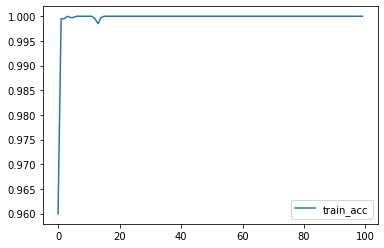

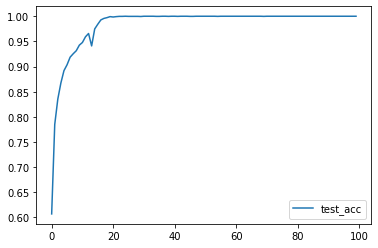

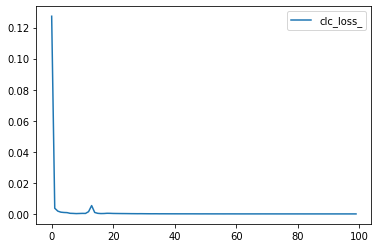

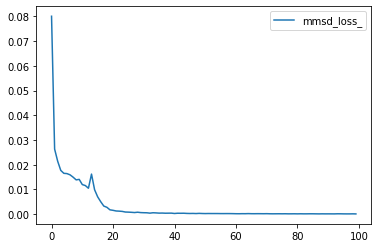

In [21]:
string=['train_acc','test_acc','clc_loss_','mmsd_loss_']
for i in string:
    plt.plot(eval(i),label=i)
    plt.legend()
    plt.show()

In [22]:

import tensorflow as tf

def transfer_learning_model():
    # Load the pre-trained model (base model)
    base_model = Model()  # Assuming the base model 'Model' is already defined

    # Freeze all convolutional layers (the first few layers)
    for layer in base_model.layers:
        if isinstance(layer, tf.keras.layers.Conv1D):
            layer.trainable = False

    # Modify the output layer of the base model to have 10 classes
    x = base_model.output[0]  # Use only the first output from base model (y1)
    x = tf.keras.layers.Dense(128, activation='relu')(x)  # Dense layer for further processing
    output = tf.keras.layers.Dense(10, activation='softmax')(x)  # 10 classes output

    # Create the new transfer learning model
    transfer_model = tf.keras.Model(inputs=base_model.input, outputs=output)

    # Compile the new model with Adam optimizer and categorical cross-entropy loss
    transfer_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
                           loss=tf.keras.losses.CategoricalCrossentropy(from_logits=False),
                           metrics=['accuracy'])

    # Print the summary of the transfer model to inspect it
    transfer_model.summary()

    return transfer_model

# Create the transfer learning model
transfer_model = transfer_learning_model()


Model: "model_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 3072, 1)]         0         
                                                                 
 conv1d_5 (Conv1D)           (None, 192, 16)           1040      
                                                                 
 batch_normalization_5 (Batc  (None, 192, 16)          64        
 hNormalization)                                                 
                                                                 
 max_pooling1d_5 (MaxPooling  (None, 96, 16)           0         
 1D)                                                             
                                                                 
 conv1d_6 (Conv1D)           (None, 96, 32)            1568      
                                                                 
 batch_normalization_6 (Batc  (None, 96, 32)           128 

In [23]:
import tensorflow as tf
import numpy as np


# Convert to tf.data.Dataset
train_dataset = tf.data.Dataset.from_tensor_slices((DX_train, Dy_train))
test_dataset = tf.data.Dataset.from_tensor_slices((DX_test, Dy_test))

train_dataset = train_dataset.shuffle(4000).batch(128, drop_remainder=True)
test_dataset = test_dataset.batch(4000, drop_remainder=True)

# Compile the transfer model
optimizer = Adam(learning_rate=0.0001)
loss = tf.keras.losses.CategoricalCrossentropy(from_logits=False)
transfer_model.compile(optimizer=optimizer, loss=loss, metrics=['accuracy'])

# Example of compiling and training the model
epochs = 30

# Train the model using the transfer learning setup
history = transfer_model.fit(train_dataset, epochs=epochs, validation_data=(DX_test, Dy_test))

Epoch 1/30
37/37 [==============================] - 2s 25ms/step - loss: 0.0014 - accuracy: 0.9998 - val_loss: 0.0039 - val_accuracy: 0.9983
Epoch 2/30
37/37 [==============================] - 1s 17ms/step - loss: 0.0016 - accuracy: 0.9998 - val_loss: 0.0041 - val_accuracy: 0.9975
Epoch 3/30
37/37 [==============================] - 1s 17ms/step - loss: 0.0011 - accuracy: 0.9998 - val_loss: 0.0037 - val_accuracy: 0.9983
Epoch 4/30
37/37 [==============================] - 1s 16ms/step - loss: 0.0010 - accuracy: 0.9998 - val_loss: 0.0068 - val_accuracy: 0.9966
Epoch 5/30
37/37 [==============================] - 1s 17ms/step - loss: 0.0019 - accuracy: 0.9998 - val_loss: 0.0022 - val_accuracy: 1.0000
Epoch 6/30
37/37 [==============================] - 1s 16ms/step - loss: 0.0014 - accuracy: 1.0000 - val_loss: 0.0048 - val_accuracy: 0.9975
Epoch 7/30
37/37 [==============================] - 1s 17ms/step - loss: 0.0042 - accuracy: 0.9983 - val_loss: 0.0047 - val_accuracy: 0.9975
Epoch 8/30
37

In [23]:
import tensorflow as tf
import numpy as np


# Convert to tf.data.Dataset
train_dataset = tf.data.Dataset.from_tensor_slices((DNX_train, DNy_train))
test_dataset = tf.data.Dataset.from_tensor_slices((DNX_test, DNy_test))

train_dataset = train_dataset.shuffle(4000).batch(128, drop_remainder=True)
test_dataset = test_dataset.batch(4000, drop_remainder=True)

# Example of compiling and training the model
epochs = 50

# Train the model using the transfer learning setup
history = transfer_model.fit(train_dataset, epochs=epochs, validation_data=test_dataset)

Epoch 1/50
37/37 [==============================] - 2s 15ms/step - loss: 1.9788 - accuracy: 0.2542
Epoch 2/50
37/37 [==============================] - 0s 11ms/step - loss: 1.4950 - accuracy: 0.6459
Epoch 3/50
37/37 [==============================] - 0s 11ms/step - loss: 1.1153 - accuracy: 0.7884
Epoch 4/50
37/37 [==============================] - 0s 11ms/step - loss: 0.8094 - accuracy: 0.8613
Epoch 5/50
37/37 [==============================] - 0s 11ms/step - loss: 0.6024 - accuracy: 0.9077
Epoch 6/50
37/37 [==============================] - 0s 11ms/step - loss: 0.4668 - accuracy: 0.9217
Epoch 7/50
37/37 [==============================] - 0s 11ms/step - loss: 0.3887 - accuracy: 0.9206
Epoch 8/50
37/37 [==============================] - 0s 11ms/step - loss: 0.3129 - accuracy: 0.9362
Epoch 9/50
37/37 [==============================] - 0s 12ms/step - loss: 0.2851 - accuracy: 0.9341
Epoch 10/50
37/37 [==============================] - 0s 12ms/step - loss: 0.2406 - accuracy: 0.9424
Epoch 11/

In [24]:
test_lossAN, test_accAN = transfer_model.evaluate(ANX_test, ANy_test)
print('The recognition accuracy of the test setAN is:', test_accAN)

test_lossBN, test_accBN = transfer_model.evaluate(BNX_test, BNy_test)
print('The recognition accuracy of the test setBN is:', test_accBN)

test_lossCN, test_accCN = transfer_model.evaluate(CNX_test, CNy_test)
print('The recognition accuracy of the test setCN is:', test_accCN)

test_lossDN, test_accDN = transfer_model.evaluate(DNX_test, DNy_test)
print('The recognition accuracy of the test setDN is:', test_accDN)

38/38 [==============================] - 1s 6ms/step - loss: 0.3912 - accuracy: 0.8598
The recognition accuracy of the test setAN is: 0.8597816824913025
38/38 [==============================] - 0s 5ms/step - loss: 0.2791 - accuracy: 0.9144
The recognition accuracy of the test setBN is: 0.9143576622009277
38/38 [==============================] - 0s 5ms/step - loss: 0.1329 - accuracy: 0.9505
The recognition accuracy of the test setCN is: 0.9504618048667908
38/38 [==============================] - 0s 6ms/step - loss: 0.0653 - accuracy: 0.9799
The recognition accuracy of the test setDN is: 0.9798826575279236


In [24]:
test_lossA, test_accA = transfer_model.evaluate(AX_test, Ay_test)
print('The recognition accuracy of the test setA is:', test_accA)

test_lossB, test_accB = transfer_model.evaluate(BX_test, By_test)
print('The recognition accuracy of the test setB is:', test_accB)

test_lossC, test_accC = transfer_model.evaluate(CX_test, Cy_test)
print('The recognition accuracy of the test setC is:', test_accC)

test_lossD, test_accD = transfer_model.evaluate(DX_test, Dy_test)
print('The recognition accuracy of the test setD is:', test_accD)

38/38 [==============================] - 0s 5ms/step - loss: 0.3260 - accuracy: 0.9060
The recognition accuracy of the test setA is: 0.9059613943099976
38/38 [==============================] - 0s 5ms/step - loss: 0.3050 - accuracy: 0.9236
The recognition accuracy of the test setB is: 0.9235936403274536
38/38 [==============================] - 0s 6ms/step - loss: 0.0604 - accuracy: 0.9798
The recognition accuracy of the test setC is: 0.9798488616943359
38/38 [==============================] - 0s 6ms/step - loss: 0.0042 - accuracy: 0.9975
The recognition accuracy of the test setD is: 0.997485339641571
